Well use a GenericCascadeCase and we will load the example dataset, generated with OpenFOAM.
We don't necessarily need a complete dataset for postprocessing procedures.

In [1]:
from ntrfc.turbo.cascade_case.solution import GenericCascadeCase
from ntrfc.turbo.cascade_case.post import blade_loading_cp, blade_loading_mais, compute_avdr_inout_massave
import pyvista as pv
import importlib.resources


pv.set_jupyter_backend('trame')

inlet_path =  importlib.resources.files("ntrfc") / "data/openfoam_cascade_case/boundary/inlet.vtp"
outlet_path = importlib.resources.files("ntrfc") / "data/openfoam_cascade_case/boundary/outlet.vtp"
blade_path = importlib.resources.files("ntrfc") / "data/openfoam_cascade_case/boundary/blade_wall.vtp"
fluid_path = importlib.resources.files("ntrfc") / "data/openfoam_cascade_case/internal.vtu"

case = GenericCascadeCase()

case.read_meshes(inlet_path,"inlet")
case.read_meshes(outlet_path,"outlet")
case.read_meshes(blade_path,"blade")
case.read_meshes(fluid_path,"fluid")


In [2]:
case.set_bladeslice_midz()

working with pv.PolyData, dataarrays can be used for postprocessing
ratio of cleaned sites: 0.832749708187427


/home/many/PycharmProjects/NTRfC/ntrfc/turbo/pointcloud_methods.py:52: UserWarning: Warning: the position of ssPoly and psPoly in the return of extractSidePolys changed. In case of unexpected results of your application, check the usage of ssPoly and psPoly
  warnings.warn(


In [3]:
_,_,_,_ ,fig= blade_loading_cp(case,pressurevar="p", densityvar="rho", velvar="U")

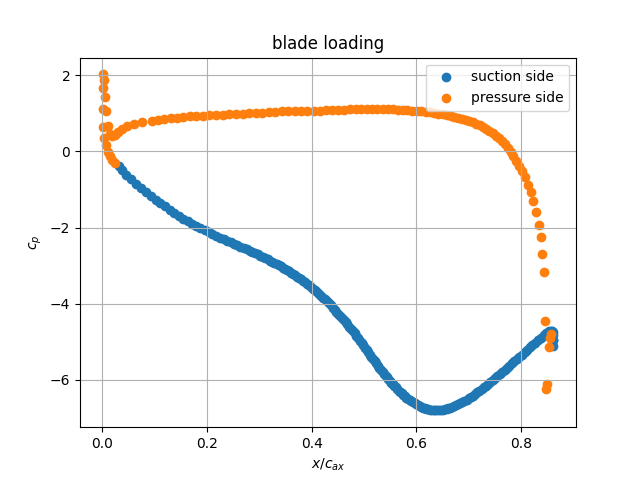

In [4]:
from IPython.display import Image
Image(fig, width=400, height=400)

In [5]:
avdr =compute_avdr_inout_massave(case,densityvar="rho", velvar="U")
print(avdr)


2.60963336411068


In [6]:
_,_,_,_ ,fig= blade_loading_mais(case,pressurevar="p", densityvar="rho", velvar="U")

/home/many/PycharmProjects/NTRfC/ntrfc/fluid/isentropic.py:36: RuntimeWarning: invalid value encountered in sqrt
  y = np.sqrt(2 / (kappa - 1) * ((p_frestream / p_blade) ** ((kappa - 1) / kappa) - 1))


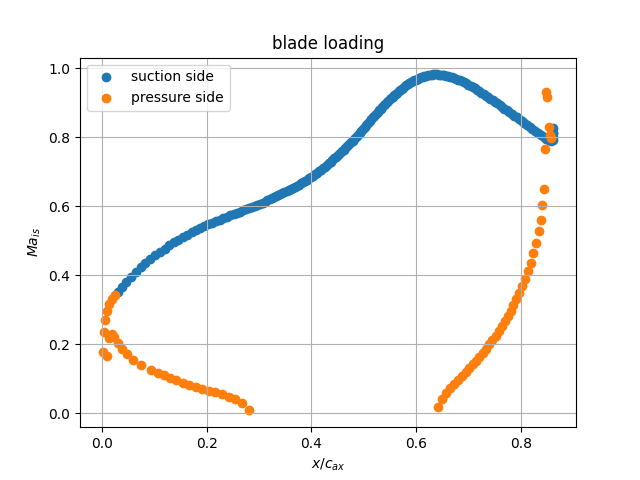

In [8]:
from IPython.display import Image
Image(fig, width=400, height=400)
